In [1]:
import numpy as np
import matplotlib.pyplot as plt
import scipp as sc
from matplotlib.colors import LogNorm
from scipy.optimize import curve_fit
from fitting import *
from matplotlib.ticker import ScalarFormatter
import matplotlib.ticker as ticker
from iminuit.cost import LeastSquares
import ipywidgets as ipw

import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['axes.labelsize'] = 18

In [2]:
def FWHM(data_x, data_y):
    if np.sum(data_y) == 0:
        data_y = np.ones(len(data_y))*1e-5
        mean = np.sum(data_x*data_y)/np.sum(data_y)
        std = 0
        FWHM = 0
    else:
        mean = np.sum(data_x*data_y)/np.sum(data_y)
        std = np.sqrt( np.sum(data_y*(data_x - mean)**2)/np.sum(data_y) )
        FWHM = 2.355*std
    return FWHM, mean, std


def gauss(x, A1, mu1, sigma1):
    return A1*np.exp(-(x-mu1)**2/(2*sigma1**2))

def inc_distr(x, A1, mu1, sigma1, A2, mu2, sigma2):
    return  2*A1*np.exp(-(x-mu1)**2/(2*sigma1**2))+ A2*np.exp(-(x-mu2)**2/(2*sigma2**2))

ref = 2*np.pi/ np.array([7.2528, 5.1285, 4.1874,3.6264])


In [ ]:
from ToF_conversion_high_res import *
pos = ['upper', 'lower'] #'upper', 'cent', 'lower'
for p in pos:
    o = conv(p, 'incoherent', 'high_res')
    o.dataset()

0.009668565550687947
(165000, 10) (165000, 10)
(165000, 10) (165000, 10)
Data_reduced/incoherent_high_res_dataredu_cent.txt


In [ ]:
pos = ['upper', 'cent', 'lower'] #'upper', 'cent', 'lower'
powder_inc = np.hstack([np.loadtxt(f'Data_reduced/incoherent_high_res_dataredu_{p}.txt').T for p in pos])
#powder_inc = np.loadtxt('out_of_plane_inc_dataredu_0_new').T


In [5]:
qx = sc.array(dims=["row"], values=powder_inc[3], unit="Å^(-1)")
qy = sc.array(dims=["row"], values=powder_inc[4], unit="Å^(-1)")
deltaE = sc.array(dims=["row"], values=powder_inc[2], unit="meV")
Q = sc.array(dims=["row"], values=np.sqrt(powder_inc[3]**2+powder_inc[4]**2+powder_inc[5]**2), unit="Å^(-1)")

recording = sc.DataArray(
    data=sc.array(dims=["row"], values=powder_inc[0], unit="Å^(-1)", variances=(powder_inc[1])**2), 
    coords={"qx": qx, "qy": qy, "deltaE":deltaE, "Q":Q}
)


slicedQ_inc = recording.bin(deltaE=300, Q=100)



slicedQ_inc = slicedQ_inc.bins.mean()
slicedQ_inc


<scipp.DataArray>
Dimensions: Sizes[deltaE:300, Q:100, ]
Coordinates:
* Q                         float64           [1/Å]  (Q [bin-edge])  [1.25493e-05, 0.0199831, ..., 1.9771, 1.99707]
* deltaE                    float64            [meV]  (deltaE [bin-edge])  [-0.116818, -0.116075, ..., 0.105477, 0.106221]
Data:
                            float64           [1/Å]  (deltaE, Q)  [nan, nan, ..., 0, 0]  [nan, nan, ..., 0, 0]

<>:37: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:47: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:37: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:47: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/var/folders/qf/1p_ffz6j5ljc117p2xzz4gsm0000gn/T/ipykernel_4595/2383573458.py:37: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax[0].set_ylabel('$\hbar \omega$ [meV]')
/var/folders/qf/1p_ffz6j5ljc117p2xzz4gsm0000gn/T/ipykernel_4595/2383573458.py:47: SyntaxWarning: "\h" is an inva

(np.float64(5.560012482166997), np.float64(0.35026529034817133), np.float64(2.3609394828734596))


┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 13.16                      │              Nfcn = 186              │
│ EDM = 1.89e-06 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name   │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ A1     │   0.516   │   0.009   │            │            │         │         │       │
│ 1 │ mu1    │ 0.347e-3  │ 0.033e-3  │            │            │         │         │       │
│ 2 │ sigma1 │ 2.353e-3  │ 0.024e-3  │            │            │         │         │       │
└───┴────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌────────┬───────────────────────────────┐
│        │        A1       mu1    sigma1 │
├────────┼───────────────────────────────┤
│     A1 │  8.11e-05  -18.5e-9 -129.0e-9 │
│    mu1 │  -18.5e-9  1.11e-09    0.1e-9 │
│ sigma1 │ -129.0e-9    0.1e-9  5.88e-10 │
└────────┴───────────────────────────────┘

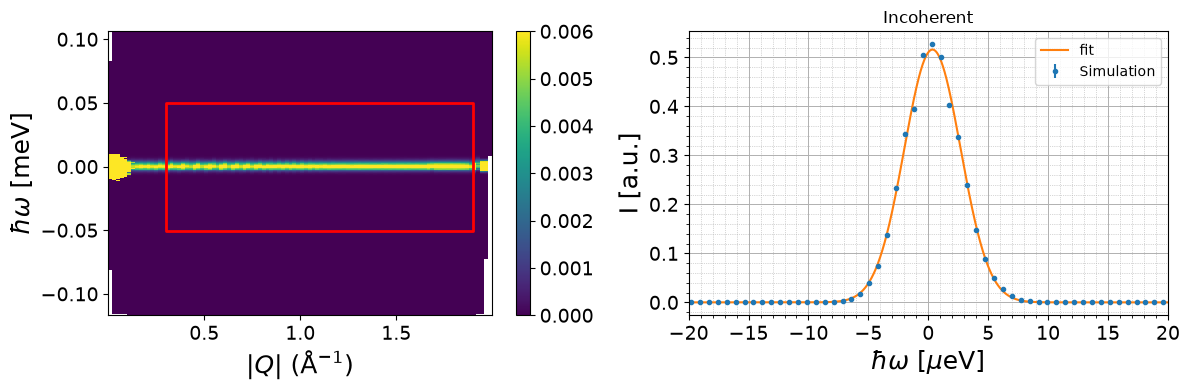

In [6]:
# Lets fit!
E_min_bla = -1 * sc.Unit('meV')
E_max_bla = 1 * sc.Unit('meV')

E_min = -0.05 * sc.Unit('meV')
E_max = 0.05 * sc.Unit('meV')

Q_min_bla = 0 * sc.Unit('Å^(-1)')
Q_max_bla = 2 * sc.Unit('Å^(-1)')

Q_min = 0.3 * sc.Unit('Å^(-1)')
Q_max = 1.9 * sc.Unit('Å^(-1)')

p_bla = slicedQ_inc['Q',Q_min_bla:Q_max_bla]['deltaE', E_min_bla:E_max_bla]

p6 = slicedQ_inc['Q',Q_min:Q_max]['deltaE', E_min:E_max]
p7 = sc.sum(p6, dim='Q')

# Gauss fit for line
Q = p7.coords['deltaE'].values
Q  = (Q[:-1] + Q[1:]) / 2.0

guess_pow = {'A1': 0.03, 'mu1':0, 'sigma1': 2.57e-3, 'A2': 0.03, 'mu2':0, 'sigma2': 2.57e-3}

lim_pow = {}# {'A1': (0.01,0.5), 'mu1':(-0.1,0.1), 'sigma1':(2.5e-3,0.1)}

#pow_fit = fit(Q, p7.values, np.sqrt(p7.variances), inc_distr, guess_pow, limits=lim_pow)
pow_fit = fit(Q, p7.values, np.sqrt(p7.variances), gauss,  {'A1': 0.03, 'mu1':0, 'sigma1': 2.57e-3})
#pow_fit.hesse()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

im = ax[0].pcolormesh(p_bla.coords['Q'].values, p_bla.coords['deltaE'].values, p_bla.values, vmin=0, vmax = 0.006) #norm= LogNorm(vmin=1e-5, vmax=1)
cbar = plt.colorbar(im)
#cbar.set_label('I [a.u.]')
ax[0].set_xlabel('$|Q|$ (Å$^{-1}$)')
ax[0].set_ylabel('$\hbar \omega$ [meV]')
# Plot the rectangle using fill_between
ax[0].fill_between([0.3,1.9],min(Q), max(Q),  color='none', edgecolor='red', lw=2) #0.14,0.17


q_range = np.linspace(min(Q), max(Q), 10000)
ax[1].errorbar(Q*1e3, p7.values, p7.variances, fmt='.', label='Simulation')
ax[1].plot(q_range*1e3, gauss(q_range, *pow_fit.values), '-', label='fit')
ax[1].set_title('Incoherent')
ax[1].legend(fontsize=10)
ax[1].set_xlabel('$\hbar \omega$ [$\mu$eV]')
ax[1].set_ylabel('I [a.u.]')
ax[1].grid()
ax[1].set_xlim(-20,20)
ax[1].grid(True, which='major', linestyle='-', linewidth=0.7)
ax[1].minorticks_on()
ax[1].grid(True, which='minor', linestyle=':', linewidth=0.5)

fig.tight_layout()
#p7.plot(title='$Na_2Ca_3Al_2F_{14}$',  ax=ax[1])
print(FWHM(Q*1e3, p7.values))
plt.savefig('Storage/incoherent_limits.pdf', format='pdf', bbox_inches='tight')

#print(pow_fit.values['sigma1']*2.355*1e3, pow_fit.values['mu1']*1e3,pow_fit.values['sigma2']*2.355*1e3, pow_fit.values['mu2']*1e3, FWHM(Q*1e3, p7.values)[0])
pow_fit.hesse()


In [ ]:
pos = ['upper', 'cent', 'lower'] #'upper', 'cent', 'lower'
powder = np.hstack([np.loadtxt(f'Data_reduced/powder_high_res_dataredu_{p}.txt').T for p in pos])

In [ ]:
# powder = np.loadtxt('out_of_plane_NaC_dataredu_0_new').T

In [ ]:
mean = {'res1':0, 'res2':0,'res3':0, 'res1_err':0, 'res2_err':0,'res3_err':0 }


qh = sc.array(dims=["row"], values=powder[3], unit="Å^(-1)")
qk = sc.array(dims=["row"], values=powder[4], unit="Å^(-1)")
ql = sc.array(dims=["row"], values=powder[5], unit="Å^(-1)")
deltaE = sc.array(dims=["row"], values=powder[2], unit="meV")
Q = sc.array(dims=["row"], values=np.sqrt(powder[3]**2+powder[4]**2+powder[5]**2), unit="Å^(-1)") #powder[5]**2

recording = sc.DataArray(
    data=sc.array(dims=["row"], values=powder[0], unit="Å^(-1)", variances=(powder[1])**2), 
    coords={"qh": qh, "qk": qk, "ql": ql, "deltaE":deltaE, "Q":Q}
)

slicedQ = recording.bin(deltaE=500, Q=200)

slicedQ = slicedQ.bins.mean()
slicedQ

<scipp.DataArray>
Dimensions: Sizes[deltaE:500, Q:200, ]
Coordinates:
* Q                         float64           [1/Å]  (Q [bin-edge])  [1.03609e-06, 0.010042, ..., 1.99816, 2.0082]
* deltaE                    float64            [meV]  (deltaE [bin-edge])  [-0.18293, -0.182254, ..., 0.154294, 0.15497]
Data:
                            float64           [1/Å]  (deltaE, Q)  [nan, nan, ..., nan, nan]  [nan, nan, ..., nan, nan]

<>:80: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:80: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/var/folders/qf/1p_ffz6j5ljc117p2xzz4gsm0000gn/T/ipykernel_3893/1946117290.py:80: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax[0].set_ylabel('$\hbar \omega$ [meV]')


(np.float64(55.99369993067995), np.float64(11.031613440574263), np.float64(23.776518017273865))
1 1.0473281234713472 0.0004357793907147244
2 0.044273508259549045 6.411935835623911e-06
3 0.03613578704485356 3.782776924895892e-06
4 -0.023408698881363262 1.8580227420884099e-06


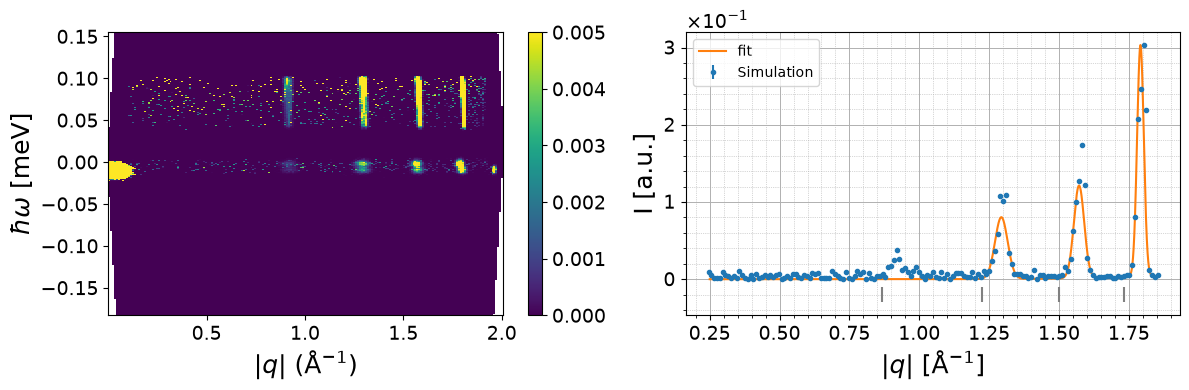

In [ ]:
E_min_bla = -1 * sc.Unit('meV')
E_max_bla = 1 * sc.Unit('meV')

E_min = -0.05 * sc.Unit('meV')
E_max = 0.05 * sc.Unit('meV')

Q_min_bla = 0 * sc.Unit('Å^(-1)')
Q_max_bla = 2 * sc.Unit('Å^(-1)')

Q_min = 0.25 * sc.Unit('Å^(-1)')
Q_max = 1.85 * sc.Unit('Å^(-1)')

p_bla = slicedQ['Q',Q_min_bla:Q_max_bla]['deltaE', E_min_bla:E_max_bla]

p6 = slicedQ['Q',Q_min:Q_max]['deltaE', E_min:E_max]
p7 = sc.sum(p6, dim='deltaE')

# Gauss fit for line
Q = p7.coords['Q'].values
Q  = (Q[:-1] + Q[1:]) / 2.0
q_range = np.linspace(0.25, 1.85, 10000)

pE = slicedQ['Q',Q_min:Q_max]['deltaE', E_min:E_max]
pE = sc.sum(p6, dim='Q')

# Gauss fit for line
E = pE.coords['deltaE'].values
E  = (E[:-1] + E[1:]) / 2.0
print(FWHM(E*1e3, pE.values))


# guess_pow = {'A1': 0.5e-3, 'mu1':0.873, 'sigma1': 0.04,
#         'A2': 2e-3, 'mu2':1.24, 'sigma2': 0.03,
#         'A3': 3.1e-3, 'mu3':1.5, 'sigma3': 0.03,'b':0}
# lim_pow = {'A1':(0.3e-3,1e-3),'mu1':(0.8,9), 'sigma1':(0.01,0.05),
#             'A2':(1.5e-3,3e-3),'mu2':(1.2,1.3),'sigma2':(0.01,0.1),
#            'A3': (2.7e-3,4e-3),'mu3':(1.45,1.55),'sigma3':(0.01,0.1)}


guess_pow = {'A1': 0.46e-1, 'mu1':0.86631167, 'sigma1': 0.02,
        'A2': 1e-1, 'mu2':1.22515069, 'sigma2': 0.015,
        'A3': 1.3e-1, 'mu3':1.500498, 'sigma3': 0.015,
        'A4': 3.2e-1, 'mu4':1.73262335, 'sigma4': 0.015,'b':0}
lim_pow = {'A2': (0.8e-1,1e-1),
           'A3': (1.2e-1,1.5e-1),
            'A4': (3e-1,4e-1)} 
fix_pow ={'A1':0.46e-3, 'A2':2e-3, 'A3': 3.1e-3, 'A4':2}

#'A1':(0.2e-3,0.7e-3),'mu1':(0.8,0.88), 'sigma1':(0.015,0.05),
#             'A2':(1.5e-3,2.1e-3),'mu2':(1.2,1.246),'sigma2':(0.01,0.1),
#            'A3': (2.7e-3,4e-3),'mu3':(1.45,1.55),'sigma3':(0.008,0.1)}


def gaussN(x, A1, mu1, sigma1, A2, mu2, sigma2, A3, mu3, sigma3,A4, mu4, sigma4, b):
    return A1*np.exp(-(x-mu1)**2/(2*sigma1**2)) + A2*np.exp(-(x-mu2)**2/(2*sigma2**2)) + A3*np.exp(-(x-mu3)**2/(2*sigma3**2)) + A4*np.exp(-(x-mu4)**2/(2*sigma4**2)) + b

pow_fit = fit(Q, p7.values, p7.variances, gaussN, guess_pow, limits= lim_pow) #  , fixed_params=fix_pow

for r in range(1,5):
    print(r,pow_fit.values[f'sigma{r}']*2*np.sqrt(2)*np.log(2),pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))
    # mean[f'res{r}']+= pow_fit.values[f'sigma{r}']*2*np.sqrt(2)*np.log(2)/(pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))**2
    # mean[f'res{r}_err'] += 1/(pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))**2


fig, ax = plt.subplots(1, 2, figsize=(12, 4))

#ax[1].plot(q_range, gaussN(q_range, **guess_pow), '-', color = 'green', label='guess')


#pow_fit.hesse() limits=lim_pow , p0=guess_pow
pow_fit.hesse()
incr =[0,170,240,300,350]
im = ax[0].pcolormesh(p_bla.coords['Q'].values, p_bla.coords['deltaE'].values, p_bla.values, vmin=0, vmax=0.005) #norm= LogNorm(vmin=1e-7, vmax=1e-4), vmin=0, vmax=0.000007
cbar = plt.colorbar(im)
#int_mat += p_bla.values

#cbar = ax[0].colorbar(im)
#cbar.set_label('I [a.u.]')
ax[0].set_xlabel('$|q|$ (Å$^{-1}$)')
ax[0].set_ylabel('$\hbar \omega$ [meV]')
# Plot the rectangle using fill_between
#ax[0].fill_between([0.25, 1.65], -0.1, 0.1, color='none', edgecolor='crimson', lw=2)



ax[1].errorbar(Q, p7.values, p7.variances, fmt='.', label='Simulation')
#inten += p7.values

ax[1].plot(q_range, gaussN(q_range, *pow_fit.values), '-', label='fit')
#plt.set_title(f'Analyser {i}', fontsize = 12)
ax[1].legend(fontsize=10, loc = 'upper left')
ax[1].set_xlabel('$|q|$ [Å$^{-1}$]')
ax[1].set_ylabel('I [a.u.]')
ax[1].grid()
#ax[1].set_ylim(0,0.0002)
#ax[1].set_xlim(0,1.75)
ax[1].yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0))
ax[1].errorbar(ref,-0.02*np.ones((len(ref))),fmt='.',yerr = 0.01*np.ones((len(ref))), markersize= 0, color='grey') 

ax[1].grid(True, which='major', linestyle='-', linewidth=0.7)
ax[1].minorticks_on()
ax[1].grid(True, which='minor', linestyle=':', linewidth=0.5)

plt.savefig('Storage/powder.pdf', format='pdf', bbox_inches='tight')

fig.tight_layout()
# print(pow_fit.values['sigma1']*2.355)
# pow_fit.hesse()

#lim=[20,80,110,140,160]
#ax[1].plot(Q[lim], [0,0,0,0,0], 'x', markersize=10)
# print(Q[lim[0:1]], p7.values[lim[0:1]])
# for i in range(0,4):
#     print(FWHM(Q[lim[i]:lim[i+1]], p7.values[lim[i]:lim[i+1]]))

In [ ]:
ref_2 = 2*np.pi/ np.array([7.2528, 5.1285, 4.1874,3.6264, 3.2435, 2.9609,2.7413,2.5642,2.4176,2.2935,2.1868, 2.0937,2.0116,1.8727,1.8132,1.7591,1.7095,1.6639,1.6218])
len(ref_2)

19

In [ ]:
pos = ['upper', 'cent', 'lower'] #'upper', 'cent', 'lower'
powder_2n = np.hstack([np.loadtxt(f'powder_dataredu_{p}').T for p in pos])
#powder_2n = np.loadtxt(f'out_of_plane_NaC_2n_dataredu').T

FileNotFoundError: powder_dataredu_upper not found.

In [ ]:
mean = {'res1':0, 'res2':0,'res3':0, 'res1_err':0, 'res2_err':0,'res3_err':0 }


qh = sc.array(dims=["row"], values=powder_2n[3], unit="Å^(-1)")
qk = sc.array(dims=["row"], values=powder_2n[4], unit="Å^(-1)")
ql = sc.array(dims=["row"], values=powder_2n[5], unit="Å^(-1)")
deltaE = sc.array(dims=["row"], values=powder_2n[2], unit="meV")
Q = sc.array(dims=["row"], values=np.sqrt(powder_2n[3]**2+powder_2n[4]**2+powder_2n[5]**2), unit="Å^(-1)") #powder[5]**2

recording = sc.DataArray(
    data=sc.array(dims=["row"], values=powder_2n[0], unit="Å^(-1)", variances=(powder_2n[1])**2), 
    coords={"qh": qh, "qk": qk, "ql": ql, "deltaE":deltaE, "Q":Q}
)

slicedQ = recording.bin(deltaE=500, Q=330)

slicedQ = slicedQ.bins.mean()
slicedQ

<scipp.DataArray>
Dimensions: Sizes[deltaE:500, Q:330, ]
Coordinates:
* Q                         float64           [1/Å]  (Q [bin-edge])  [1.54771e-06, 0.0120671, ..., 3.96956, 3.98163]
* deltaE                    float64            [meV]  (deltaE [bin-edge])  [-0.640886, -0.638324, ..., 0.637317, 0.639878]
Data:
                            float64           [1/Å]  (deltaE, Q)  [nan, nan, ..., nan, nan]  [nan, nan, ..., nan, nan]

<>:103: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
<>:103: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
/var/folders/qf/1p_ffz6j5ljc117p2xzz4gsm0000gn/T/ipykernel_85691/813419388.py:103: SyntaxWarning: "\h" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\h"? A raw string is also an option.
  ax[0].set_ylabel('$\hbar \omega$ [meV]')


(np.float64(26.375231776104346), np.float64(-0.04115462002575123), np.float64(11.199673790277854))
Given names not corresponding to function, overwriting...
0 0.20264782990789082 0.00011330284746374463
1 0.11683729360362112 6.22731388226938e-05
2 0.10964359965158149 8.038715656408898e-05
3 0.09840039135658286 5.715961670736178e-05
4 0.10336918454073574 0.00011295485823749973
5 0.08926957055607238 0.000111371524307118
6 0.09069149904237271 0.00013447306379754095
7 0.08706175507950364 0.0001552935165174462
8 0.07036280884854319 9.191939130485695e-05
9 0.08453118947791324 8.025612304860631e-05
10 0.06910519940541998 4.1273141665097624e-05
11 0.2396889104095093 0.0010835196165871423
12 0.060113827840824724 3.0380144405149704e-05
13 0.054969498553375816 2.3172432094564662e-05
14 0.045974629159478274 2.0620030238684165e-05
15 0.04732331896596686 2.6619201395697906e-05
16 0.03774973071580459 9.480988517034617e-06
17 0.02565498936968954 6.041039719945536e-06
18 0.03896361534542705 2.3899392829

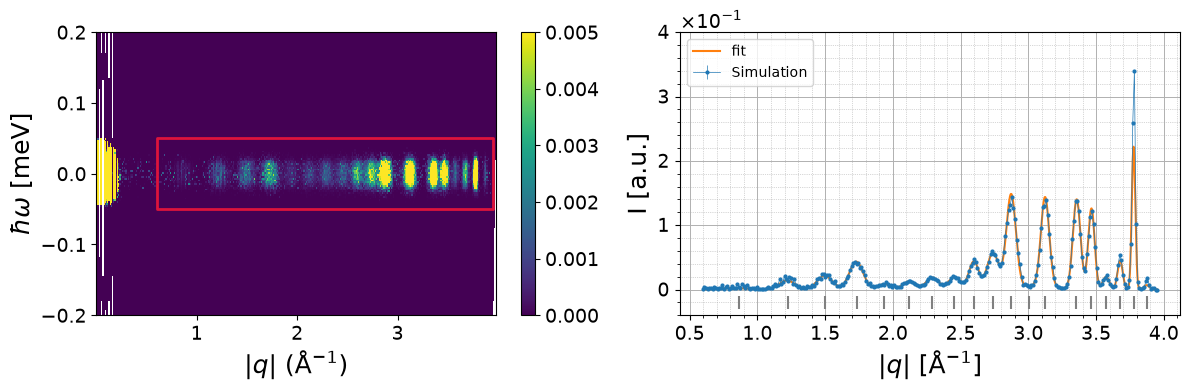

In [ ]:
E_min_bla = -1 * sc.Unit('meV')
E_max_bla = 1 * sc.Unit('meV')

E_min = -0.05 * sc.Unit('meV')
E_max = 0.05 * sc.Unit('meV')

Q_min_bla = 0 * sc.Unit('Å^(-1)')
Q_max_bla = 4 * sc.Unit('Å^(-1)')

Q_min = 0.6 * sc.Unit('Å^(-1)')
Q_max = 3.95 * sc.Unit('Å^(-1)')

p_bla = slicedQ['Q',Q_min_bla:Q_max_bla]['deltaE', E_min_bla:E_max_bla]

p6 = slicedQ['Q',Q_min:Q_max]['deltaE', E_min:E_max]
p7 = sc.sum(p6, dim='deltaE')

# Gauss fit for line
Q = p7.coords['Q'].values
Q  = (Q[:-1] + Q[1:]) / 2.0
q_range = np.linspace(0.6, 3.95, 10000)

pE = slicedQ['Q',Q_min:Q_max]['deltaE', E_min:E_max]
pE = sc.sum(p6, dim='Q')

# Gauss fit for line
E = pE.coords['deltaE'].values
E  = (E[:-1] + E[1:]) / 2.0
print(FWHM(E*1e3, pE.values))


# guess_pow = {'A1': 0.5e-3, 'mu1':0.873, 'sigma1': 0.04,
#         'A2': 2e-3, 'mu2':1.24, 'sigma2': 0.03,
#         'A3': 3.1e-3, 'mu3':1.5, 'sigma3': 0.03,'b':0}
# lim_pow = {'A1':(0.3e-3,1e-3),'mu1':(0.8,9), 'sigma1':(0.01,0.05),
#             'A2':(1.5e-3,3e-3),'mu2':(1.2,1.3),'sigma2':(0.01,0.1),
#            'A3': (2.7e-3,4e-3),'mu3':(1.45,1.55),'sigma3':(0.01,0.1)}

guess_pow = {'A0': 0.1e-1, 'mu0':ref_2[0], 'sigma0': 0.02,
        'A1': 0.2e-1, 'mu1':ref_2[1], 'sigma1': 0.03,
        'A2': 0.3e-1, 'mu2':ref_2[2], 'sigma2': 0.03,
        'A3': 0.5e-1, 'mu3':ref_2[3], 'sigma3': 0.03,
        'A4': 0.1e-1, 'mu4':ref_2[4], 'sigma4': 0.03,
        'A5': 0.1e-1, 'mu5':ref_2[5], 'sigma5': 0.03,
        'A6': 0.2e-1, 'mu6':ref_2[6], 'sigma6': 0.03,
        'A7': 0.2e-1, 'mu7':ref_2[7], 'sigma7': 0.03,
        'A8': 0.5e-1, 'mu8':ref_2[8], 'sigma8': 0.03,
        'A9': 0.6e-1, 'mu9':ref_2[9], 'sigma9': 0.03,
        'A10': 1.5e-1, 'mu10':ref_2[10], 'sigma10': 0.03,
        'A11': 0.1e-1, 'mu11':ref_2[11], 'sigma11': 0.03,
        'A12': 1.5e-1, 'mu12':ref_2[12], 'sigma12': 0.02,
        'A13': 1.5e-1, 'mu13':ref_2[13], 'sigma13': 0.02,
        'A14': 1.2e-1, 'mu14':ref_2[14], 'sigma14': 0.015,
        'A15': 0.3e-1, 'mu15':ref_2[15], 'sigma15': 0.015,
        'A16': 0.5e-1, 'mu16':ref_2[16], 'sigma16': 0.015,
        'A17': 3e-1, 'mu17':ref_2[17], 'sigma17': 0.015,
        'A18': 0.2e-1, 'mu18':ref_2[18], 'sigma18': 0.015,'b':0}

lim_pow = {}#{'A2': (0.8e-1,1e-1),
        #    'A3': (1.2e-1,1.5e-1),
        #     'A4': (3e-1,4e-1)} 
fix_pow ={'A1':0.46e-3, 'A2':2e-3, 'A3': 3.1e-3, 'A4':2}

#'A1':(0.2e-3,0.7e-3),'mu1':(0.8,0.88), 'sigma1':(0.015,0.05),
#             'A2':(1.5e-3,2.1e-3),'mu2':(1.2,1.246),'sigma2':(0.01,0.1),
#            'A3': (2.7e-3,4e-3),'mu3':(1.45,1.55),'sigma3':(0.008,0.1)}

def gen_gaussN(N,names):
    def gaussN(x, *par):
        p = dict(zip(names, par))
        x = np.asarray(x, dtype=float)
        y = np.full_like(x, p['b'])
        for n in range(N):
            y += p[f'A{n}'] * np.exp(-(x - p[f'mu{n}'])**2 / (2 * p[f'sigma{n}']**2))
        return y
    return gaussN  
names = list(guess_pow.keys())  
gaussN = gen_gaussN(19,names)

pow_fit = fit(Q, p7.values, p7.variances, gaussN, guess_pow, limits= lim_pow) #  , fixed_params=fix_pow

for r in range(19):
    print(r,pow_fit.values[f'sigma{r}']*2*np.sqrt(2)*np.log(2),pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))
    # mean[f'res{r}']+= pow_fit.values[f'sigma{r}']*2*np.sqrt(2)*np.log(2)/(pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))**2
    # mean[f'res{r}_err'] += 1/(pow_fit.errors[f'sigma{r}']*2*np.sqrt(2)*np.log(2))**2


fig, ax = plt.subplots(1, 2, figsize=(12, 4))

#ax[1].plot(q_range, gaussN(q_range, *guess_pow.values()), '-', color = 'green', label='guess')


#pow_fit.hesse() limits=lim_pow , p0=guess_pow
#pow_fit.hesse()
incr =[0,170,240,300,350]
im = ax[0].pcolormesh(p_bla.coords['Q'].values, p_bla.coords['deltaE'].values, p_bla.values, vmin=0, vmax=0.005) #norm= LogNorm(vmin=1e-7, vmax=1e-4), vmin=0, vmax=0.000007
cbar = plt.colorbar(im)
#int_mat += p_bla.values

#cbar = ax[0].colorbar(im)
#cbar.set_label('I [a.u.]')
ax[0].set_xlabel('$|q|$ (Å$^{-1}$)')
ax[0].set_ylabel('$\hbar \omega$ [meV]')
# Plot the rectangle using fill_between
ax[0].fill_between([0.6, 3.95], -0.05, 0.05, color='none', edgecolor='crimson', lw=2)
ax[0].set_ylim(-0.2,0.2)


ax[1].errorbar(Q, p7.values, p7.variances, fmt='.-', label='Simulation', markersize = 4, linewidth = 0.5)
#inten += p7.values

ax[1].plot(q_range, gaussN(q_range, *pow_fit.values), '-', label='fit')
#plt.set_title(f'Analyser {i}', fontsize = 12)
ax[1].legend(fontsize=10, loc = 'upper left')
ax[1].set_xlabel('$|q|$ [Å$^{-1}$]')
ax[1].set_ylabel('I [a.u.]')
ax[1].grid()
ax[1].set_ylim(-0.04,0.4)
#ax[1].set_xlim(-0,0.5)
ax[1].yaxis.set_major_formatter(ticker.ScalarFormatter(useMathText=True))
ax[1].ticklabel_format(style='sci', axis='y', scilimits=(0, 0)) 
ax[1].errorbar(ref_2,-0.02*np.ones((len(ref_2))),fmt='.',yerr = 0.01*np.ones((len(ref_2))), markersize= 0, color='grey')

ax[1].grid(True, which='major', linestyle='-', linewidth=0.7)
ax[1].minorticks_on()
ax[1].grid(True, which='minor', linestyle=':', linewidth=0.5)

#plt.savefig('NaC_2n.pdf', format='pdf', bbox_inches='tight')

fig.tight_layout()
# print(pow_fit.values['sigma1']*2.355)
# pow_fit.hesse()

#lim=[20,80,110,140,160]
#ax[1].plot(Q[lim], [0,0,0,0,0], 'x', markersize=10)
# print(Q[lim[0:1]], p7.values[lim[0:1]])
# for i in range(0,4):
#     print(FWHM(Q[lim[i]:lim[i+1]], p7.values[lim[i]:lim[i+1]]))